In [2]:
import os, subprocess

try:
    import cv2
    ss_ready = hasattr(cv2, "ximgproc") and hasattr(cv2.ximgproc, "segmentation")
except Exception:
    ss_ready = False

if not ss_ready:
    subprocess.run("pip uninstall -y -q opencv-python opencv-python-headless "
                   "opencv-contrib-python opencv-contrib-python-headless", shell=True)
    subprocess.run("pip install -q opencv-contrib-python", shell=True)
    os.kill(os.getpid(), 9)  # restart runtime once; then run all cells again

In [3]:
import tensorflow as tf
from tensorflow.keras.applications import VGG16
from tensorflow.keras.applications.vgg16 import preprocess_input, decode_predictions
import numpy as np
import cv2
from google.colab import files
from google.colab.patches import cv2_imshow

# CLASSIFIER: VGG16 pre-trained on ImageNet
# include_top=True keeps VGG16's 1000-class head
model = VGG16(weights='imagenet', include_top=True)

553467096/553467096 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


In [4]:
def get_region_proposals(img, max_regions=200):
    try:
        ss = cv2.ximgproc.segmentation.createSelectiveSearchSegmentation()
        ss.setBaseImage(img)
        ss.switchToSelectiveSearchFast()  # Fast mode
        boxes = [(x, y, w, h) for (x, y, w, h) in ss.process() if w > 40 and h > 40]
        if boxes:
            return boxes[:max_regions]
    except Exception:
        pass

    # Fallback: multi-scale sliding windows
    H, W = img.shape[:2]
    boxes = []

    for s in (0.6, 0.4, 0.25):
        bw, bh = int(W*s), int(H*s)
        for y in range(0, H-bh+1, max(1, bh//2)):
            for x in range(0, W-bw+1, max(1, bw//2)):
                boxes.append((x, y, bw, bh))

    return boxes[:max_regions]

Saving park_object_detection.jpg to park_object_detection (2).jpg


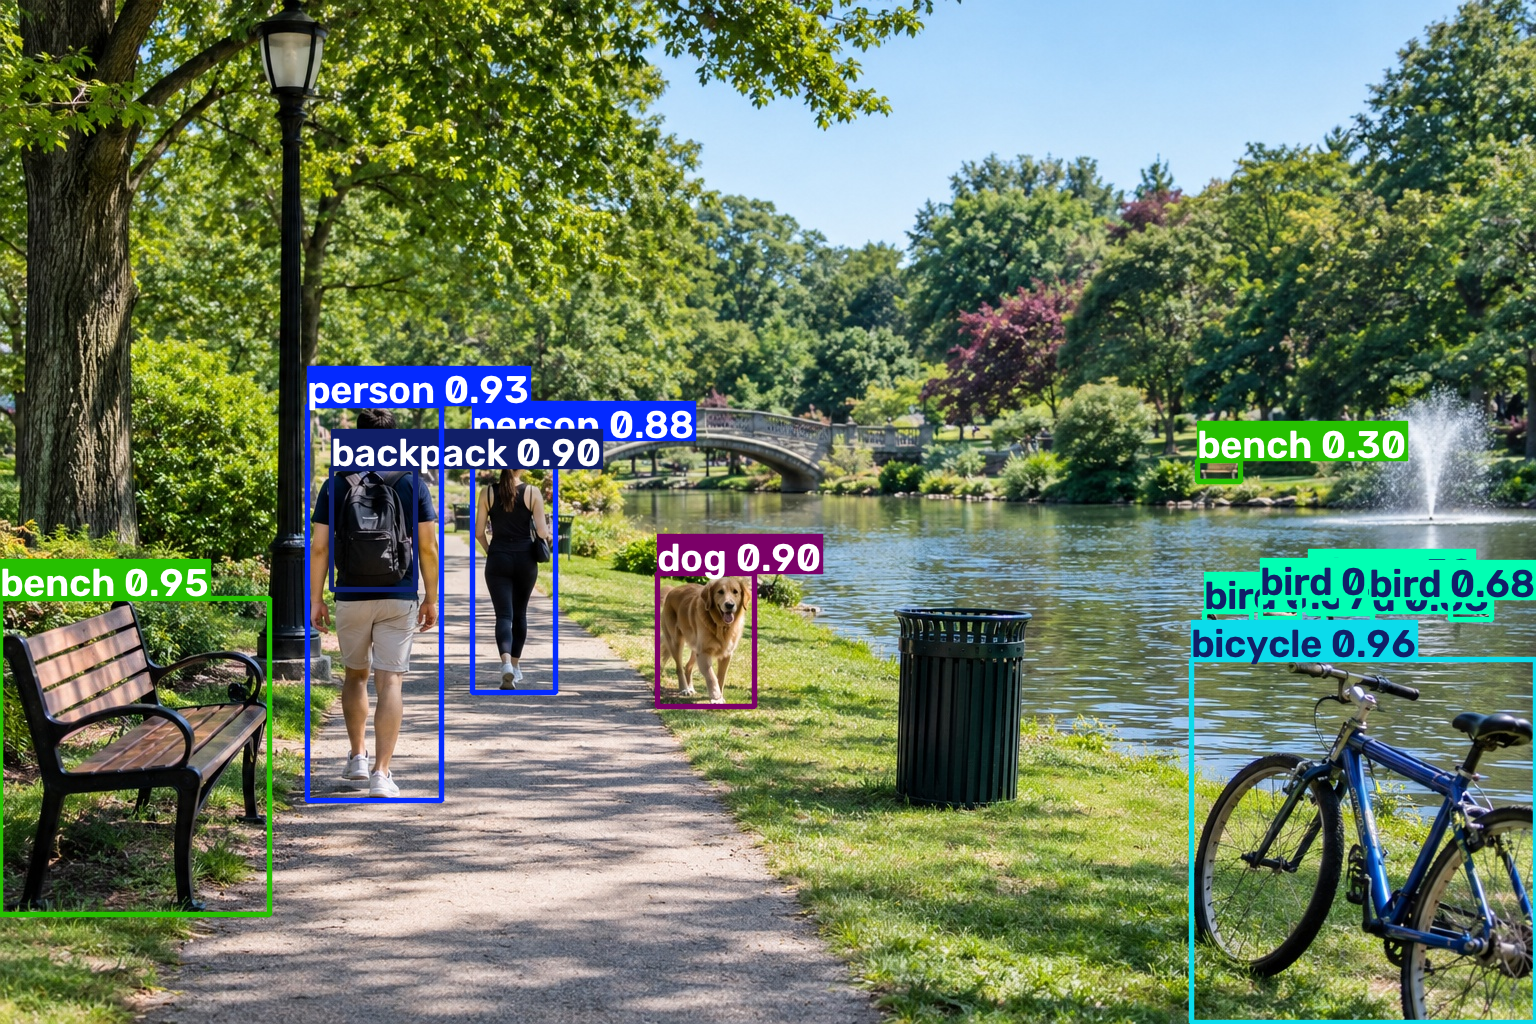

In [8]:
!pip install -q ultralytics

from ultralytics import YOLO
from google.colab import files
from google.colab.patches import cv2_imshow

# Load a larger pretrained model
model = YOLO("yolov8m.pt")

# Upload image
uploaded = files.upload()
image_path = next(iter(uploaded))

# Detect objects
results = model.predict(
    source=image_path,
    conf=0.15,
    iou=0.45,
    imgsz=960,
    verbose=False
)

# Display detections
result_image = results[0].plot()
cv2_imshow(result_image)